# Quant Analytics with KDB-X Python

### Keep your notebook. Keep your pandas. Lose the wait.

Runnable end-to-end (~10 min). This notebook covers three concepts:

1. **Your workflow doesn't change.** Same notebook, same Python, largely the same API.
2. **The core quant operations get much faster.** Measured in Section 5.
3. **q is optional.** The pandas-style API covers most work; your AI assistant covers the rest (Section 9).

KDB-X Python embeds the KDB-X vector engine in your Python process. Data lives in kdb columnar memory; code stays Python.

Setup: Python 3.10+, `pip install --upgrade pykx`, free license at [developer.kx.com](https://developer.kx.com/products/kdb-x/install).

### Installs
Recommend to create a venv to run this notebook from

In [ ]:
!pip install pyarrow pandas numpy

In [2]:
!pip install -qq --upgrade pykx

*Recommend restarting your runtime after installs*

### Imports

In [3]:
import pykx as kx
import pandas as pd
import numpy as np
from datetime import date, timedelta
from pathlib import Path

print('pykx    :', kx.__version__)
print('licensed:', kx.licensed)
print('pandas  :', pd.__version__)


Welcome to KDB-X Community Edition!
For Community support, please visit https://kx.com/slack
Tutorials can be found at https://github.com/KxSystems/tutorials
Ready to go beyond the Community Edition? Email preview@kx.com

pykx    : 4.0.0
licensed: True
pandas  : 3.0.3


---
## 1. 20M rows of market data in seconds

Self-contained: a synthetic but realistic trading day: 40 symbols, a 20M-row quote feed, and 100K executions. Per-symbol price levels, intraday drift, bps-scale spreads. In production this comes from your kdb database (Section 8), Parquet (Section 7), or CSV.

In [4]:
%%time
syms = ['AAPL', 'MSFT', 'NVDA', 'AMZN', 'GOOG', 'META', 'BRK.B', 'LLY', 'AVGO', 'JPM',
        'TSLA', 'XOM', 'UNH', 'V', 'PG', 'MA', 'COST', 'JNJ', 'HD', 'WMT',
        'MRK', 'ABBV', 'NFLX', 'CVX', 'BAC', 'AMD', 'CRM', 'KO', 'PEP', 'TMO',
        'ORCL', 'LIN', 'ACN', 'ADBE', 'MCD', 'CSCO', 'ABT', 'WFC', 'IBM', 'GE']

n = 20_000_000                      # quote rows, scale freely
day = date(2025, 1, 6)
rng = np.random.default_rng(42)

DAY_NS = 86_400_000_000_000
base = rng.uniform(20, 500, len(syms)).round(2)   # per-symbol price level
beta = rng.uniform(0.5, 2.0, len(syms))           # per-symbol intraday sensitivity

def make_day(rows):
    t = np.sort(rng.integers(0, DAY_NS, rows))
    ts = np.datetime64(day) + t.astype('timedelta64[ns]')
    i = rng.integers(0, len(syms), rows)
    drift = 0.01 * np.sin(2 * np.pi * t / DAY_NS)
    px = base[i] * (1 + beta[i] * drift + rng.normal(0, 0.003, rows))
    return ts, i, px

ts, i, mid = make_day(n)
spread = mid * rng.uniform(1, 5, n) / 10000       # 1-5 bps
quote = kx.Table(data={
    'time': ts,
    'sym':  np.array(syms)[i],
    'bid':  (mid - spread / 2).round(4),
    'ask':  (mid + spread / 2).round(4),
})

m = 100_000
ts, i, px = make_day(m)
execs = kx.Table(data={
    'time': ts,
    'sym':  np.array(syms)[i],
    'price': px.round(2),
    'size': rng.integers(1, 500, m),
    'side': np.where(rng.random(m) < 0.5, 'BUY', 'SELL'),
})

print(f'quote: {len(quote):,}   execs: {len(execs):,}')

quote: 20,000,000   execs: 100,000
CPU times: user 5.02 s, sys: 190 ms, total: 5.21 s
Wall time: 5.26 s


In [5]:
quote.head(10)

,time,sym,bid,ask
,,,,
0,2025.01.06D00:00:00.004614018,AVGO,81.4621,81.4844
1,2025.01.06D00:00:00.008414053,TSLA,197.67,197.6954
2,2025.01.06D00:00:00.010800279,TMO,347.1207,347.1794
3,2025.01.06D00:00:00.020371127,WFC,248.872,248.9153
4,2025.01.06D00:00:00.021465653,LIN,484.6926,484.83
5,2025.01.06D00:00:00.029174477,LIN,488.1818,488.2807
6,2025.01.06D00:00:00.031982426,GE,341.8146,341.9174
7,2025.01.06D00:00:00.034553975,KO,41.0427,41.0523
8,2025.01.06D00:00:00.038540082,AVGO,82.1899,82.2109


In [6]:
quote.dtypes

,columns,datatypes
,,
0,time,"""kx.TimestampAtom"""
1,sym,"""kx.SymbolAtom"""
2,bid,"""kx.FloatAtom"""
3,ask,"""kx.FloatAtom"""


`.head(10)` and `.dtypes` are pandas idioms, here running against a 20M-row table in kdb memory.

---
## 2. You already know this API

KDB-X Python tables implement most of the pandas API ([reference](https://code.kx.com/pykx/4.0/user-guide/advanced/Pandas_API.html)). 

In [7]:
# boolean masks, straight on the kdb table
quote[quote['sym'] == 'AAPL'].head(3)

,time,sym,bid,ask
,,,,
0,2025.01.06D00:00:00.243898647,AAPL,389.8056,389.9697
1,2025.01.06D00:00:00.702400931,AAPL,392.2831,392.3615
2,2025.01.06D00:00:01.147591169,AAPL,391.7786,391.8686


In [8]:
# column assignment, integer slicing
quote['spread'] = quote['ask'] - quote['bid']
quote.iloc[:3]

,time,sym,bid,ask,spread
,,,,,
0,2025.01.06D00:00:00.004614018,AVGO,81.4621,81.4844,0.0223
1,2025.01.06D00:00:00.008414053,TSLA,197.67,197.6954,0.0254
2,2025.01.06D00:00:00.010800279,TMO,347.1207,347.1794,0.0587


In [9]:
# sort, shape, aggregate
print(quote.shape)
quote.sort_values(by='spread', ascending=False).head(3)

(pykx.LongAtom(pykx.q('20000000')), pykx.LongAtom(pykx.q('5')))


,time,sym,bid,ask,spread
,,,,,
0,2025.01.06D07:07:39.424031017,META,500.7889,501.0393,0.2504
1,2025.01.06D05:26:21.210172693,META,500.3633,500.6134,0.2501
2,2025.01.06D04:08:16.836145711,META,500.7096,500.9594,0.2498


The same applies to `loc`, `rename`, `drop_duplicates`, `agg`, `merge`. Next: the same analytic in both engines, timed. One full copy first, so pandas competes on its own memory:

In [10]:
%%time
quote_df = quote.pd()          # full 20M-row copy, on purpose
execs_df = execs.pd()
quote_df.info(memory_usage='deep')

<class 'pandas.DataFrame'>
RangeIndex: 20000000 entries, 0 to 19999999
Data columns (total 5 columns):
 #   Column  Dtype         
---  ------  -----         
 0   time    datetime64[ns]
 1   sym     str           
 2   bid     float64       
 3   ask     float64       
 4   spread  float64       
dtypes: datetime64[ns](1), float64(3), str(1)
memory usage: 824.5 MB
CPU times: user 2.92 s, sys: 212 ms, total: 3.13 s
Wall time: 3.14 s


### Same analytic, twice: average spread and quote count per symbol

In [11]:
%%time
# pandas
quote_df.groupby('sym').agg(
    avg_spread=('spread', 'mean'),
    n_quotes=('spread', 'count'),
).head(5)

CPU times: user 272 ms, sys: 24.8 ms, total: 297 ms
Wall time: 296 ms


,avg_spread,n_quotes
sym,,
AAPL,0.117399,500962
ABBV,0.056992,499872
ABT,0.024719,500735
ACN,0.052936,498955
ADBE,0.059317,499373


In [12]:
%%time
# KDB-X Python: runs inside the vector engine
quote.select(
    columns=kx.Column('spread').avg().name('avg_spread') &
            kx.Column('spread').count().name('n_quotes'),
    by=kx.Column('sym'),
).head(5)

CPU times: user 24.9 ms, sys: 417 μs, total: 25.3 ms
Wall time: 25.3 ms


,avg_spread,n_quotes
sym,,
AAPL,0.1173988,500962
ABBV,0.05699249,499872
ABT,0.02471896,500735
ACN,0.05293617,498955
ADBE,0.05931697,499373


Same readability, order-of-magnitude gap, no tuning. Filters compose the same way:

In [13]:
%%time
# pandas
quote_df[(quote_df['sym'] == 'AAPL') & (quote_df['ask'] > quote_df['bid'] * 1.0002)]['ask'].mean()

CPU times: user 96.4 ms, sys: 3.99 ms, total: 100 ms
Wall time: 100 ms


np.float64(391.55976923367876)

In [14]:
%%time
# KDB-X Python
quote.select(
    columns=kx.Column('ask').avg().name('avg_ask'),
    where=(kx.Column('sym') == 'AAPL') & (kx.Column('ask') > kx.Column('bid') * 1.0002),
)

CPU times: user 20.1 ms, sys: 932 μs, total: 21.1 ms
Wall time: 22.7 ms


,avg_ask
,
0,391.5598


### Round trips to pandas are cheap

In [15]:
per_sym = quote.select(
    columns=kx.Column('spread').avg().name('avg_spread') &
            kx.Column('spread').count().name('n_quotes'),
    by=kx.Column('sym'),
)

df_result = per_sym.pd()        # pandas
np_bids = quote['bid'].np()     # numpy, for scipy/sklearn
back_to_kx = kx.toq(df_result)  # and back

print(type(df_result).__name__, '|', type(np_bids).__name__, '|', type(back_to_kx).__name__)
df_result.head(3)

DataFrame | ndarray | KeyedTable


,avg_spread,n_quotes
sym,,
AAPL,0.117399,500962
ABBV,0.056992,499872
ABT,0.024719,500735


**Mental model:** data stays in kdb memory, queries run where the data is, you convert results, not datasets.

---
## 3. Joins & Aggregations

### 3a. VWAP of your fills, 15-minute buckets

In [16]:
%%time
# pandas: vectorized, no .apply()
tmp = execs_df.assign(
    bucket=execs_df['time'].dt.floor('15min'),
    pv=execs_df['price'] * execs_df['size'],
)
vwap_pd = (
    tmp.groupby(['sym', 'bucket'])
       .agg(pv=('pv', 'sum'), sz=('size', 'sum'))
       .assign(vwap=lambda d: d.pv / d.sz)
       [['vwap']]
)
vwap_pd.head(5)

CPU times: user 6.39 ms, sys: 1.15 ms, total: 7.53 ms
Wall time: 6.81 ms


vwap
sym  bucket                         
AAPL 2025-01-06 00:00:00  392.028498
     2025-01-06 00:15:00  392.193035
     2025-01-06 00:30:00  392.487615
     2025-01-06 00:45:00  392.203193
     2025-01-06 01:00:00  393.101967

In [17]:
%%time
# KDB-X Python: wavg and xbar are engine primitives
vwap_kx = execs.select(
    columns=kx.Column('size').wavg(kx.Column('price')).name('vwap'),
    by=kx.Column('sym') & kx.Column('time').minute.xbar(15),
)
vwap_kx.head(5)

CPU times: user 1.92 ms, sys: 64 μs, total: 1.99 ms
Wall time: 1.99 ms


pykx.KeyedTable(pykx.q('
sym  time | vwap    
----------| --------
AAPL 00:00| 392.0285
AAPL 00:15| 392.193 
AAPL 00:30| 392.4876
AAPL 00:45| 392.2032
AAPL 01:00| 393.102 
'))

`wavg`, `xbar`, `mavg`, `ema`, `prev`: operations that take several lines of scaffolding in pandas are single primitives in the engine.

### 3b. The asof join

*What was the prevailing quote when each execution filled?*

In [18]:
print(f'{len(execs):,} execs vs {len(quote):,} quotes')

100,000 execs vs 20,000,000 quotes


In [19]:
%%time
# pandas: scans the full feed regardless of exec count
joined_pd = pd.merge_asof(execs_df, quote_df, on='time', by='sym')
joined_pd[['time', 'sym', 'price', 'side', 'bid', 'ask']].head(5)

CPU times: user 621 ms, sys: 21.3 ms, total: 643 ms
Wall time: 643 ms


,time,sym,price,side,bid,ask
0,2025-01-06 00:00:00.593749374,ADBE,198.15,SELL,198.2311,198.3184
1,2025-01-06 00:00:01.610942363,ORCL,376.79,BUY,377.3617,377.4223
2,2025-01-06 00:00:02.129824437,PG,233.70,BUY,232.3963,232.4909
3,2025-01-06 00:00:03.054843377,ACN,175.84,BUY,176.2274,176.2483
4,2025-01-06 00:00:03.119555091,COST,285.19,BUY,286.9459,287.0490


In [20]:
%%time
# g# on sym, both tables (standard TCA prep)
execs.update(kx.Column('sym').call('`g#'), inplace=True)
quote.update(kx.Column('sym').call('`g#'), inplace=True)
kx.q.meta(quote)

CPU times: user 41.9 ms, sys: 9.47 ms, total: 51.4 ms
Wall time: 51.5 ms


,t,f,a
c,,,
time,"""p""",,
sym,"""s""",,g
bid,"""f""",,
ask,"""f""",,
spread,"""f""",,


In [21]:
%%time
# native aj; merge_asof is the pandas-style alias for the same join
joined_kx = kx.q.aj(['sym', 'time'], execs, quote)
joined_kx.head(5)

CPU times: user 73.7 ms, sys: 1.6 ms, total: 75.2 ms
Wall time: 75.2 ms


,time,sym,price,size,side,bid,ask,spread
,,,,,,,,
0,2025.01.06D00:00:00.593749374,ADBE,198.15,174,SELL,198.2311,198.3184,0.0873
1,2025.01.06D00:00:01.610942363,ORCL,376.79,126,BUY,377.3617,377.4223,0.0606
2,2025.01.06D00:00:02.129824437,PG,233.7,334,BUY,232.3963,232.4909,0.0946
3,2025.01.06D00:00:03.054843377,ACN,175.84,199,BUY,176.2274,176.2483,0.0209
4,2025.01.06D00:00:03.119555091,COST,285.19,316,BUY,286.9459,287.049,0.1031


In [22]:
%%time
# slippage vs mid, bps
slippage = joined_kx.select(
    columns=((kx.Column('price') - (kx.Column('bid') + kx.Column('ask')) / 2)
             / ((kx.Column('bid') + kx.Column('ask')) / 2) * 10000
            ).avg().name('avg_slippage_bps'),
    by=kx.Column('sym'),
)
slippage.head(5)

CPU times: user 717 μs, sys: 155 μs, total: 872 μs
Wall time: 874 μs


,avg_slippage_bps
sym,
AAPL,0.6482724
ABBV,-0.8884384
ABT,0.5063659
ACN,0.8097421
ADBE,-0.682683


`aj` binary-searches per execution, so cost scales with the executions table rather than the feed. `merge_asof` walks the entire feed.

---
## 4. 300M rows

Persist the quote feed to a date-partitioned database, clone to 15 days, keep querying. This uses ~10 GB of disk; lower `DAYS` if needed.

In [23]:
db_dir = Path.cwd() / 'pods_hdb'
db = kx.DB(path=db_dir, change_dir=False)

# sym-sort once: the s# attribute makes each partition's internal sort ~free
quote_s = quote.sort_values('sym')

# by_field='sym': sym-sorted partitions with p#, the standard production layout.
# change_dir=False again: create() reloads the DB and its own flag defaults True
db.create(quote_s, 'quote', day, by_field='sym', change_dir=False)
assert Path.cwd() == db_dir.parent, 'cwd moved into the DB; restart the kernel'
db.tables

Writing Database Partition 2025-01-06 to table quote


['quote']

In [24]:
%%time
# clone the day into 15 partitions (mostly disk-write time after the pre-sort);
# reduce DAYS for a faster build
DAYS = 15
for i_ in range(1, DAYS):
    offset = timedelta(days=i_)
    db.create(quote_s.update(kx.Column('time') + offset), 'quote', day + offset,
              by_field='sym', change_dir=False)

print(f'{DAYS} partitions in {db_dir}')

Writing Database Partition 2025-01-07 to table quote
Writing Database Partition 2025-01-08 to table quote
Writing Database Partition 2025-01-09 to table quote
Writing Database Partition 2025-01-10 to table quote
Writing Database Partition 2025-01-11 to table quote
Writing Database Partition 2025-01-12 to table quote
Writing Database Partition 2025-01-13 to table quote
Writing Database Partition 2025-01-14 to table quote
Writing Database Partition 2025-01-15 to table quote
Writing Database Partition 2025-01-16 to table quote
Writing Database Partition 2025-01-17 to table quote
Writing Database Partition 2025-01-18 to table quote
Writing Database Partition 2025-01-19 to table quote
Writing Database Partition 2025-01-20 to table quote
15 partitions in /Users/ryan/Documents/code/pykx_pods/pods_hdb
CPU times: user 879 ms, sys: 929 ms, total: 1.81 s
Wall time: 2.98 s


In [25]:
%%time
# rows per partition
db.quote.select(
    columns=kx.Column('time').count().name('rows'),
    by=kx.Column('date'),
)

CPU times: user 500 μs, sys: 1.69 ms, total: 2.19 ms
Wall time: 4.36 ms


,rows
date,
2025.01.06,20000000
2025.01.07,20000000
2025.01.08,20000000
2025.01.09,20000000
2025.01.10,20000000
2025.01.11,20000000
2025.01.12,20000000
2025.01.13,20000000
2025.01.14,20000000


In [26]:
%%time
# hourly average spread, one symbol, all 300M rows
db.quote.select(
    columns=kx.Column('spread').avg().name('avg_spread'),
    by=kx.Column('date') & kx.Column('time').minute.xbar(60),
    where=kx.Column('sym') == 'AAPL',
)

CPU times: user 80.2 ms, sys: 28.1 ms, total: 108 ms
Wall time: 344 ms


pykx.KeyedTable(pykx.q('
date       time | avg_spread
----------------| ----------
2025.01.06 00:00| 0.1176752 
2025.01.06 01:00| 0.1176125 
2025.01.06 02:00| 0.1180212 
2025.01.06 03:00| 0.1184999 
2025.01.06 04:00| 0.1185615 
2025.01.06 05:00| 0.1191751 
2025.01.06 06:00| 0.118874  
2025.01.06 07:00| 0.1186496 
2025.01.06 08:00| 0.1176856 
2025.01.06 09:00| 0.1179029 
2025.01.06 10:00| 0.1175607 
2025.01.06 11:00| 0.1179131 
2025.01.06 12:00| 0.1170605 
2025.01.06 13:00| 0.1172192 
2025.01.06 14:00| 0.1165737 
2025.01.06 15:00| 0.1162084 
2025.01.06 16:00| 0.116083  
2025.01.06 17:00| 0.1160992 
2025.01.06 18:00| 0.1164617 
2025.01.06 19:00| 0.1163066 
..
'))

In [27]:
%%time
# 15-minute TWAP mid + last mid, one symbol, 15 days
db.quote.select(
    columns=((kx.Column('bid') + kx.Column('ask')) / 2).avg().name('twap_mid') &
            ((kx.Column('bid') + kx.Column('ask')) / 2).last().name('last_mid'),
    by=kx.Column('date') & kx.Column('time').minute.xbar(15),
    where=kx.Column('sym') == 'AAPL',
)

CPU times: user 97.6 ms, sys: 28.7 ms, total: 126 ms
Wall time: 292 ms


pykx.KeyedTable(pykx.q('
date       time | twap_mid last_mid
----------------| -----------------
2025.01.06 00:00| 391.6555 392.2195
2025.01.06 00:15| 391.9534 394.7807
2025.01.06 00:30| 392.2538 391.7399
2025.01.06 00:45| 392.542  392.0365
2025.01.06 01:00| 392.8161 393.9044
2025.01.06 01:15| 393.0858 392.9156
2025.01.06 01:30| 393.3681 392.2423
2025.01.06 01:45| 393.6321 394.4909
2025.01.06 02:00| 393.8511 395.8444
2025.01.06 02:15| 394.1226 394.2111
2025.01.06 02:30| 394.3649 395.0249
2025.01.06 02:45| 394.5924 393.8532
2025.01.06 03:00| 394.8174 396.6348
2025.01.06 03:15| 395.0032 393.5298
2025.01.06 03:30| 395.2062 395.3603
2025.01.06 03:45| 395.3297 397.8462
2025.01.06 04:00| 395.4805 396.1506
2025.01.06 04:15| 395.6415 396.4799
2025.01.06 04:30| 395.7409 395.9673
2025.01.06 04:45| 395.8295 398.0858
..
'))

These queries touch only the partitions and columns they need, so results come back in seconds from disk with the same API. The partitions are memory-mapped rather than loaded: a workstation with 16 GB of RAM can query a database far larger than its memory, with the OS page cache deciding what stays resident. The pandas alternative is a DataFrame that must fit in RAM before the first query runs.

> Keep `pods_hdb`: Section 8 serves it as a live kdb process.

## 5. The benchmark


In [28]:
import gc
import platform
import statistics
import time


print('=== engines ===')
print('pykx  :', kx.__version__)
print('pandas:', pd.__version__)
print('numpy :', np.__version__)

print('\n=== hardware ===')
print('platform:', platform.platform())
try:
    import psutil
    print(f'cpus    : {psutil.cpu_count(logical=False)} physical / {psutil.cpu_count()} logical')
    print(f'ram     : {psutil.virtual_memory().total / 2**30:.0f} GiB')
except ImportError:
    print('(pip install psutil for cpu/ram details)')

=== engines ===
pykx  : 4.0.0
pandas: 3.0.3
numpy : 2.5.1

=== hardware ===
platform: macOS-15.7.4-arm64-arm-64bit-Mach-O
cpus    : 12 physical / 12 logical
ram     : 24 GiB


In [29]:
import warnings
warnings.filterwarnings('ignore', message='.*__array_function__.*')

N_RUNS = 10
WARMUP = 2

results = []     # every workload appends rows here; summarized at the end

def bench(workload, engine, fn, n_runs=N_RUNS):
    """Warm-run timer: warmups, then n_runs iterations with GC between."""
    for _ in range(WARMUP):
        fn()
    times = []
    for _ in range(n_runs):
        gc.collect()
        t0 = time.perf_counter()
        fn()
        times.append(time.perf_counter() - t0)
    row = {
        'workload': workload,
        'engine': engine,
        'mean_s': statistics.mean(times),
        'std_s': statistics.stdev(times) if len(times) > 1 else 0.0,
        'runs': n_runs,
    }
    results.append(row)
    print(f"{workload:28} {engine:8} {row['mean_s']*1000:10.1f} ms ± {row['std_s']*1000:.1f}")
    return row

### A: asof join + slippage


In [30]:
def pandas_tca():
    merged = pd.merge_asof(execs_df, quote_df, on='time', by='sym')
    mid = 0.5 * (merged['bid'] + merged['ask'])
    diff = np.where(merged['side'] == 'BUY', mid - merged['price'], merged['price'] - mid)
    merged['mid'] = mid
    merged['diff'] = diff
    merged['slippage'] = (diff / mid) * 10000
    return merged

def pykx_tca():
    merged = kx.q.aj(['sym', 'time'], execs, quote)
    mid = 0.5 * (merged['bid'] + merged['ask'])
    diff = np.where(merged['side'] == 'BUY', mid - merged['price'], merged['price'] - mid)
    merged['mid'] = mid
    merged['diff'] = diff
    merged['slippage'] = (diff / mid.np()) * 10000
    return merged

In [31]:
# Sanity check first: both engines must agree before we time anything
chk_pd = pandas_tca()['slippage'].mean()
chk_kx = float(kx.q.avg(pykx_tca()['slippage']))
print(f'mean slippage: pandas {chk_pd:.4f} | pykx {chk_kx:.4f} bps')
assert abs(chk_pd - chk_kx) < 1e-6, 'engines disagree; fix before benchmarking'

bench('A: asof join + slippage', 'pandas', pandas_tca)
bench('A: asof join + slippage', 'KDB-X Python',   pykx_tca)

mean slippage: pandas -0.0897 | pykx -0.0897 bps
A: asof join + slippage      pandas        616.7 ms ± 14.6
A: asof join + slippage      KDB-X Python       73.5 ms ± 0.2


{'workload': 'A: asof join + slippage',
 'engine': 'KDB-X Python',
 'mean_s': 0.07346871249992545,
 'std_s': 0.00020146699046660898,
 'runs': 10}

### B: OHLC + TWAP bars on the quote mid, 15-minute buckets

In [32]:
def pandas_bars():
    tmp = quote_df.assign(
        mid=0.5 * (quote_df['bid'] + quote_df['ask']),
        bucket=quote_df['time'].dt.floor('15min'),
    )
    g = tmp.groupby(['sym', 'bucket'])
    return g.agg(open=('mid', 'first'), high=('mid', 'max'),
                 low=('mid', 'min'), close=('mid', 'last'),
                 twap=('mid', 'mean'))

def pykx_bars():
    def mid():
        return (kx.Column('bid') + kx.Column('ask')) / 2
    return quote.select(
        columns=mid().first().name('open') &
                mid().max().name('high') &
                mid().min().name('low') &
                mid().last().name('close') &
                mid().avg().name('twap'),
        by=kx.Column('sym') & kx.Column('time').minute.xbar(15),
    )

bench('B: OHLC+TWAP bars', 'pandas', pandas_bars)
bench('B: OHLC+TWAP bars', 'KDB-X Python',   pykx_bars)

B: OHLC+TWAP bars            pandas        568.6 ms ± 10.6
B: OHLC+TWAP bars            KDB-X Python      227.0 ms ± 4.9


{'workload': 'B: OHLC+TWAP bars',
 'engine': 'KDB-X Python',
 'mean_s': 0.22702797080019083,
 'std_s': 0.0049437852753148395,
 'runs': 10}

### C: rolling MA(20) per symbol


In [33]:
def pandas_rolling():
    return quote_df.groupby('sym')['bid'].rolling(20).mean()

def pykx_rolling():
    return quote.update(
        columns={'ma20': kx.Column('bid').mavg(20)},
        by=kx.Column('sym'),
    )

bench('C: rolling MA(20) per sym', 'pandas', pandas_rolling)
bench('C: rolling MA(20) per sym', 'KDB-X Python',   pykx_rolling)

C: rolling MA(20) per sym    pandas       3587.6 ms ± 58.1
C: rolling MA(20) per sym    KDB-X Python      321.0 ms ± 4.5


{'workload': 'C: rolling MA(20) per sym',
 'engine': 'KDB-X Python',
 'mean_s': 0.32104735000011714,
 'std_s': 0.004534285835994003,
 'runs': 10}

In [34]:
# Results: absolute times and KDB-X Python speedup
res_df = pd.DataFrame(results)
timing = res_df.pivot_table(index='workload', columns='engine', values='mean_s')
timing['KDB-X Python speedup'] = (timing['pandas'] / timing['KDB-X Python']).round(1)
timing.round(3)

engine,KDB-X Python,pandas,KDB-X Python speedup
workload,,,
A: asof join + slippage,0.073,0.617,8.4
B: OHLC+TWAP bars,0.227,0.569,2.5
C: rolling MA(20) per sym,0.321,3.588,11.2


### Reading the results

Pandas remains a good fit for small data and its ecosystem, but as data scales up, KDB-X Python's advantage gets stronger.

With KDB-X Python, the performance multiplier grows with data size. `merge_asof` scans the full quote feed, so doubling the feed roughly doubles the pandas cost, while `aj` cost tracks the much smaller executions table. The rolling and bucketed workloads widen too as the working set outgrows CPU caches and pandas' intermediate copies add memory pressure. Memory is part of the gap too. The pandas side of this benchmark only works because Section 2 materialized `quote_df` and `execs_df` as full copies in Python memory for the 20M-row quote table before the first join runs. The KDB-X Python side queries the tables in place and copies nothing. That is the key difference: DataFrames versus memory-mapped partitions. And if your tick data already lives in kdb, pandas pays that copy out before its first query.

Limitations: warm in-process timings, one machine (specs above), seeded synthetic data, default settings for both engines.

## 6. Plotting stays Python

Aggregate in KDB-X Python, `.pd()` the small result, plot with anything. plotnine here; matplotlib/seaborn work the same.

In [ ]:
%pip install plotnine

In [36]:
from plotnine import (ggplot, aes, geom_col, geom_line, geom_text, coord_flip,
                      position_dodge, scale_fill_manual, scale_color_manual,
                      labs, theme_minimal, theme, element_text, element_line,
                      element_blank)

ENGINE_COLORS = {'KDB-X Python': '#2a78d6', 'pandas': '#898781'}

POD_THEME = theme_minimal() + theme(
    panel_grid_minor=element_blank(),
    panel_grid_major=element_line(color='#e1e0d9', size=0.4),
    axis_text=element_text(color='#898781', size=9),
    axis_title=element_text(color='#52514e', size=10),
    plot_title=element_text(color='#0b0b0b', size=13, weight='bold'),
    plot_subtitle=element_text(color='#52514e', size=10),
    legend_text=element_text(color='#52514e', size=9),
    legend_title=element_blank(),
    figure_size=(9, 4.5),
)

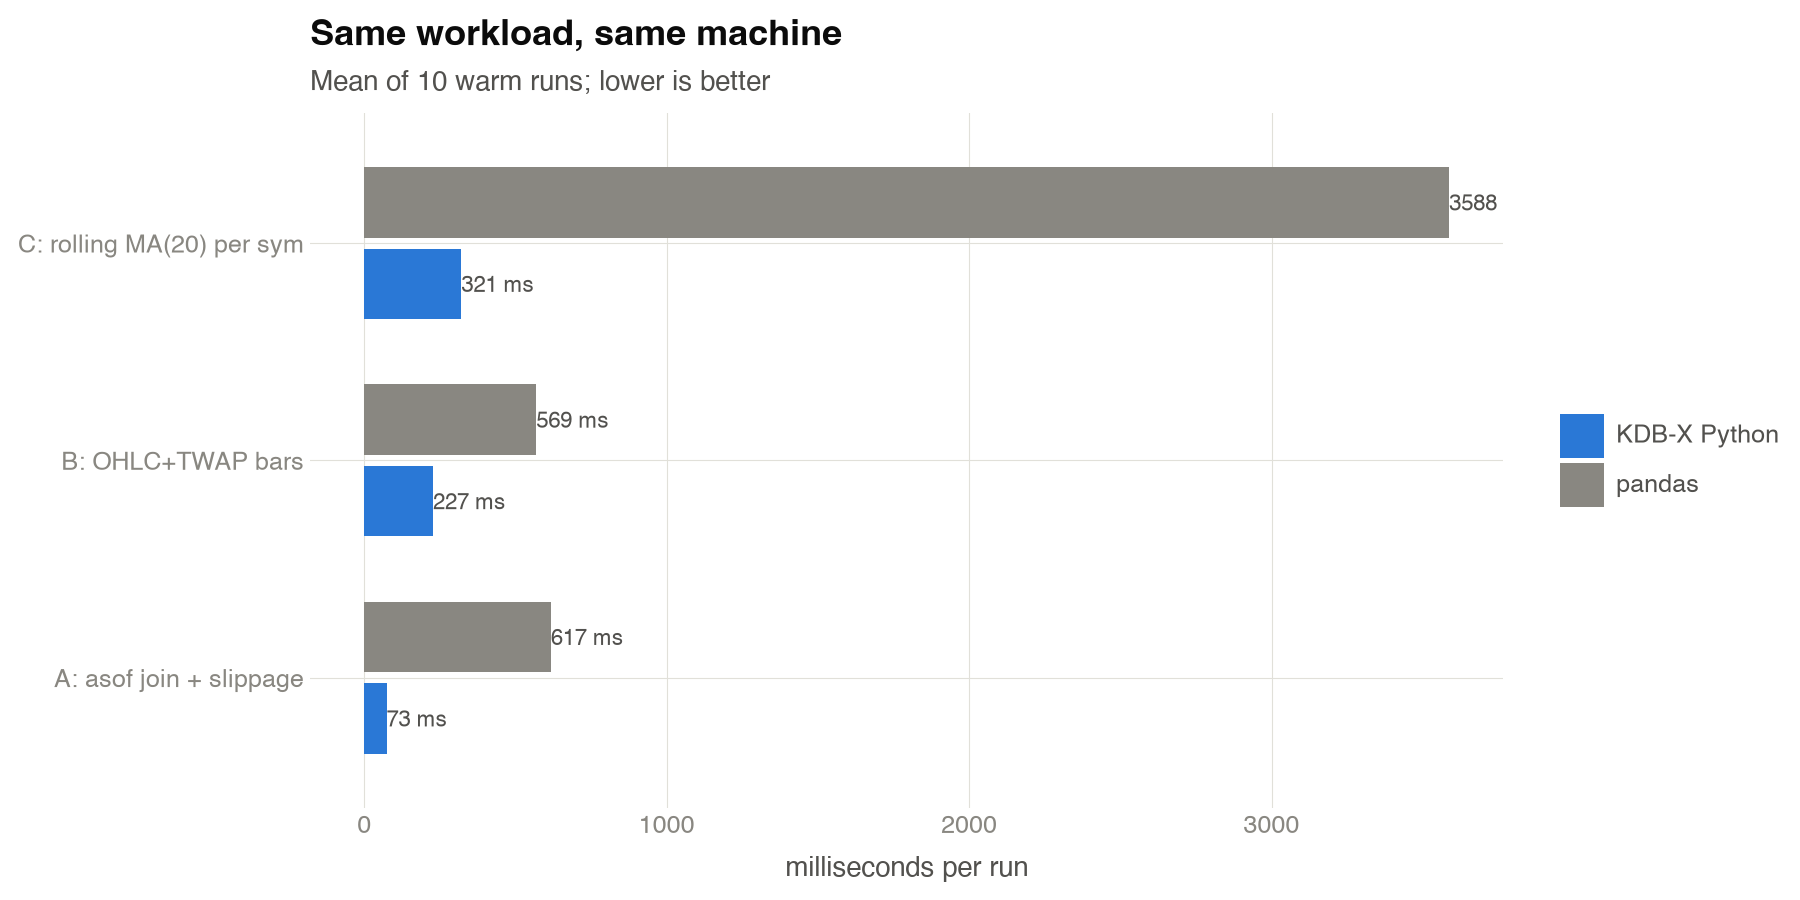

In [37]:
# Section 5 results
chart_df = res_df.copy()
chart_df['ms'] = chart_df['mean_s'] * 1000
chart_df['label'] = chart_df['ms'].round(0).astype(int).astype(str) + ' ms'

(ggplot(chart_df, aes(x='workload', y='ms', fill='engine'))
 + geom_col(position=position_dodge(width=0.75), width=0.65)
 + geom_text(aes(label='label'),
             position=position_dodge(width=0.75),
             ha='left', size=8, color='#52514e')
 + coord_flip()
 + scale_fill_manual(values=ENGINE_COLORS)
 + labs(title='Same workload, same machine',
        subtitle='Mean of 10 warm runs; lower is better',
        x='', y='milliseconds per run')
 + POD_THEME)

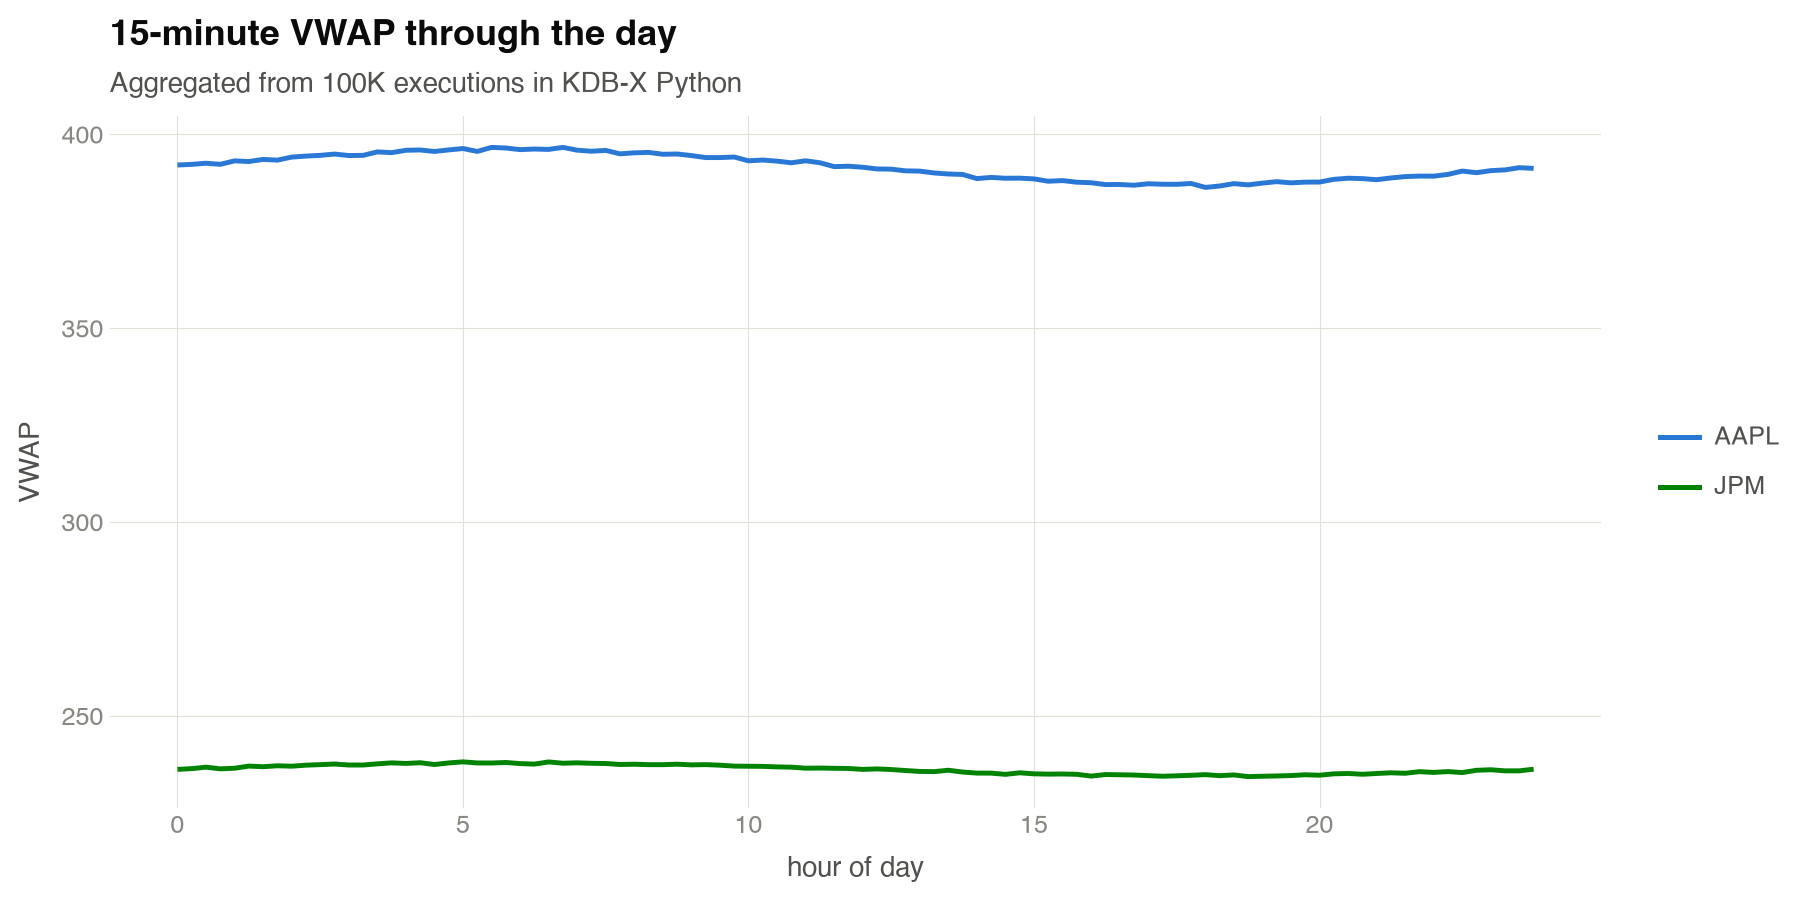

In [38]:
# Intraday VWAP of the fills, two symbols, from the Section 3a result
vwap_df = vwap_kx.pd().reset_index()
vwap_df.columns = ['sym', 'bucket', 'vwap']

def to_hours(v):
    s = str(v).split()[-1]
    hh, mm = s.split(':')[:2]
    return int(hh) + int(mm) / 60

vwap_df['hour'] = vwap_df['bucket'].map(to_hours)
two = vwap_df[vwap_df['sym'].isin(['AAPL', 'JPM'])]

(ggplot(two, aes(x='hour', y='vwap', color='sym'))
 + geom_line(size=1)
 + scale_color_manual(values={'AAPL': '#2a78d6', 'JPM': '#008300'})
 + labs(title='15-minute VWAP through the day',
        subtitle='Aggregated from 100K executions in KDB-X Python',
        x='hour of day', y='VWAP')
 + POD_THEME)

### 6b. When you want to see every tick *(optional)*

plotnine plots results: aggregates small enough to convert. Raw-tick inspection (bad prints, gaps, microstructure) is where Python plotting taps out, so the [ax module](https://github.com/KxSystems/ax) renders inside the engine instead: skia-rasterized ggplot, no conversion, no downsampling. This one reads a day of AAPL quotes straight from the Section 4 database and returns only a PNG.

In [39]:
# one-time: ax + fusion modules into ~/.kx/mod 
import io, platform, ssl, sys, urllib.request, zipfile

_os, _arm = sys.platform, platform.machine().lower() in ('arm64', 'aarch64')
_ax = {'linux': 'ax-l64.zip', 'darwin': 'ax-marm.zip' if _arm else 'ax-mi64.zip',
       'win32': 'ax-w64.zip'}[_os]
_fu = {'linux': 'fusion-l64arm.zip' if _arm else 'fusion-l64.zip',
       'darwin': 'fusion-m64.zip', 'win32': 'fusion-w64.zip'}[_os]

try:                                   # python.org macOS builds ship without CA certs wired up
    import certifi
    _ctx = ssl.create_default_context(cafile=certifi.where())
except ImportError:
    _ctx = ssl.create_default_context()

for name, repo, asset in [('ax', 'ax', _ax), ('fusion', 'fusionx', _fu)]:
    if not (Path.home() / '.kx' / 'mod' / 'kx' / name).exists():
        url = f'https://github.com/KxSystems/{repo}/releases/latest/download/{asset}'
        with urllib.request.urlopen(url, context=_ctx) as r:
            zipfile.ZipFile(io.BytesIO(r.read())).extractall(Path.home() / '.kx' / 'mod')

qp = kx.q('use `kx.ax.graphics')['qp']
print('ax graphics loaded:', len(qp), 'functions')

ax graphics loaded: 61 functions


500,962 raw quotes rendered
CPU times: user 82.6 ms, sys: 8.41 ms, total: 91 ms
Wall time: 116 ms


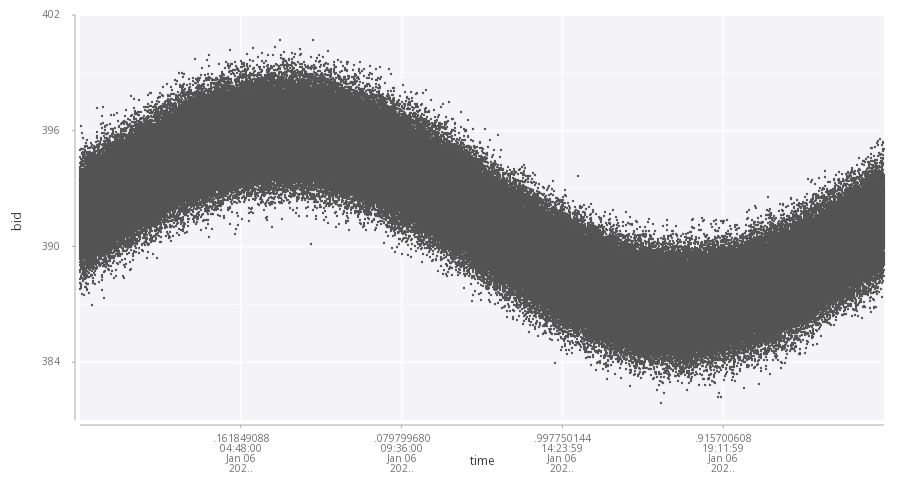

In [40]:
%%time
# every AAPL quote for one day, pulled from one HDB partition: no sampling,
# rendered where the data lives
aapl = db.quote.select(where=(kx.Column('date') == day) & (kx.Column('sym') == 'AAPL'))

png_file = Path.cwd() / 'research' / 'all_ticks.png'
png_file.parent.mkdir(exist_ok=True)
qp['png'](kx.q.hsym(str(png_file)), 900, 480)(
    qp['point'](aapl, 'time', 'bid', None)
)
print(f'{len(aapl):,} raw quotes rendered')

from IPython.display import Image
Image(str(png_file))

---
## 7. Parquet with no import

KDB-X ships a parquet module (`kx.pq`, bundled with pykx 4). `pq` maps a file as a virtual table; row groups load only when a query touches them. Hundreds of files stitch into one partitioned virtual table via `kx.pq.t` ([tutorial](https://github.com/KxSystems/tutorials/blob/main/KDB-X/Modules/parquet.md)).

In [41]:
%%time
# round-trip: write today's quotes to parquet, map it back, query in place
import pyarrow.parquet as papq

pq_file = Path.cwd() / 'research' / 'quote_day.parquet'
pq_file.parent.mkdir(exist_ok=True)
papq.write_table(quote.pa(), pq_file)

pq = kx.module.use('kx.pq')     # load the module
vt = pq.pq(Path(pq_file))       # map, not import

# parquet has no symbol type: sym arrives as strings (bytes), so filter via a
# q-side variable
kx.q['tickers'] = [b'AAPL', b'JPM', b'NVDA']

vt.select(
    columns={'avg_spread': kx.Column('spread').avg()},
    by={'sym': kx.Column('sym')},
    where=kx.Column('sym').isin(kx.Variable('tickers')),
)

CPU times: user 5.19 s, sys: 359 ms, total: 5.55 s
Wall time: 5.56 s


,avg_spread
sym,
"""AAPL""",0.1173988
"""JPM""",0.07091381
"""NVDA""",0.1296506


The mapped file is a `VirtualTable`: `select` runs against the parquet directly; a materialized result takes the full pandas API. No q anywhere. Many files combine into one partitioned virtual table via `kx.module.use('kx.pq.t')` ([tutorial](https://github.com/KxSystems/tutorials/blob/main/KDB-X/Modules/parquet.md)).

---
## 8. Connect to your team's kdb

Everything so far ran embedded. Now let's connect this notebook to a kdb server. We'll serve Section 4's database from a separate q process as a stand-in for your production HDB.

In [42]:
import shutil
import subprocess
import time as _t

# in production this process already exists and you skip straight to the connection
assert shutil.which('q'), 'no q binary on PATH; install KDB-X (developer.kx.com) or point PATH at it'

with kx.PyKXReimport():
    server = subprocess.Popen(
        ['q', str(db_dir), '-p', '5010'],
        stdin=subprocess.PIPE,          # keep stdin open: q exits on EOF
        stdout=subprocess.DEVNULL,
        stderr=subprocess.PIPE,
    )
_t.sleep(3)
if server.poll() is not None:
    raise RuntimeError('q exited: ' + server.stderr.read().decode(errors='replace')[:500])
print('q serving pods_hdb on :5010')

q serving pods_hdb on :5010


In [43]:
%%time
# query the full remote HDB; only the result is returned
try:
    with kx.SyncQConnection('localhost', 5010) as conn:
        res = conn.qsql.select(
            'quote',
            columns={'avg_spread': kx.Column('spread').avg()},
            by={'date': kx.Column('date'),
                'bucket': kx.Column('time').minute.xbar(15)},
            where=kx.Column('sym') == 'AAPL',
        ).pd()
        # q-string equivalent, if you prefer it:
        # conn('select avg_spread: avg spread by date, 15 xbar time.minute from quote where sym=`AAPL')
finally:
    server.kill()

res.head(5)

CPU times: user 10.4 ms, sys: 37.3 ms, total: 47.7 ms
Wall time: 206 ms


avg_spread
date       bucket                     
2025-01-06 0 days 00:00:00    0.117561
           0 days 00:15:00    0.118186
           0 days 00:30:00    0.117722
           0 days 00:45:00    0.117217
           0 days 01:00:00    0.117429

Production is the same three lines with your host: `kx.SyncQConnection('hdb.yourfirm.com', 5010, username=..., password=...)`. TLS via `kx.SecureQConnection`, async via `kx.AsyncQConnection`.

---
## 9. q, when you want it

Everything above stayed in Python. When you do reach for q, the KX skills for Claude cover it:

```bash
claude plugin marketplace add https://github.com/KxSystems/kx-skills
```

Then install `pykx-knowledge` and `q-knowledge` via `/plugin`. Claude converts pandas to KDB-X Python, writes and lints q (`/qlint-snippet`), and knows every API pattern in this notebook, which was itself built that way.

---
## 10. Get Started

1. `pip install --upgrade pykx` + [free license](https://developer.kx.com/products/kdb-x/install)
2. Point Section 8 at your team's host and port; that's your HDB in this notebook
3. Real data drop-ins: NYSE TAQ files via [taq](https://github.com/KxSystems/taq); realistic synthetic markets via [datagen](https://github.com/KxSystems/datagen)
4. [KDB-X Python docs](https://code.kx.com/pykx/) · [KDB-X tutorials](https://github.com/KxSystems/tutorials)

## Clean Up:

In [ ]:
# --- cleanup: remove everything this notebook wrote to disk ---
import shutil
from pathlib import Path

try:
    server.kill()                            # Section 8's q process, if still up
except Exception:
    pass

targets = [
    db_dir,                                  # pods_hdb 
    db_dir.parent / 'research',              # quote_day.parquet lives here
]
for t in targets:
    t = Path(t)
    if t.is_dir():
        shutil.rmtree(t, ignore_errors=True)
    elif t.is_file():
        t.unlink()
    print(('removed  ' if not t.exists() else 'FAILED   ') + str(t))